## **Step 1: Environment & Dependency Verification**

In [ ]:
# Cell 1 — Check our environment

import sys
import pandas as pd
import numpy as np

print("Python version:", sys.version)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Pandas version: 2.2.3
NumPy version: 2.1.3


## **Step 2: Locate and Extract the Dataset Zip File**

In [ ]:
import os

print("Files in /content:")
for file in os.listdir("/content"):
    print(file)

Files in /content:
.config
extention+of+z+alizadeh+sani+dataset.zip
sample_data


In [ ]:
import zipfile
import os

zip_path = "/content/extention+of+z+alizadeh+sani+dataset.zip"
extract_path = "/content/dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extracted successfully!")
print("\nFiles inside dataset:")

for root, dirs, files in os.walk(extract_path):
    for file in files:
        print(os.path.join(root, file))

Extracted successfully!

Files inside dataset:
/content/dataset/extention of Z-Alizadeh sani dataset.xlsx


## **Step 3: Load Excel Dataset into Pandas**

In [ ]:
# Cell 2 — List extracted files

import os

dataset_path = "/content/dataset"

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        print(os.path.join(root, file))

/content/dataset/extention of Z-Alizadeh sani dataset.xlsx


In [ ]:
# Cell 3 — Load Excel dataset

import pandas as pd

excel_path = "/content/dataset/extention of Z-Alizadeh sani dataset.xlsx"

df = pd.read_excel(excel_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (303, 59)


## **Step 4: Exploratory Data Analysis & Target Distribution Check**

In [ ]:
# Cell 4 — First look at the dataset

display(df.head())

,Age,Weight,Length,Sex,BMI,DM,HTN,Current Smoker,EX-Smoker,FH,...,Lymph,Neut,PLT,EF-TTE,Region RWMA,VHD,LAD,LCX,RCA,Cath
0,53,90,175,Male,29.387755,0,1,1,0,0,...,39,52,261,50,0,N,Stenotic,Normal,Stenotic,CAD
1,67,70,157,Fmale,28.398718,0,1,0,0,0,...,38,55,165,40,4,N,Stenotic,Stenotic,Normal,CAD
2,54,54,164,Male,20.077335,0,0,1,0,0,...,38,60,230,40,2,mild,Stenotic,Normal,Normal,CAD
3,66,67,158,Fmale,26.838648,0,1,0,0,0,...,18,72,742,55,0,Severe,Normal,Normal,Normal,Normal
4,50,87,153,Fmale,37.165193,0,1,0,0,0,...,55,39,274,50,0,Severe,Normal,Normal,Normal,Normal


In [ ]:
# Cell 5 — See all column names

print("Number of columns:", len(df.columns))
print("\nColumn names:")
for i, column in enumerate(df.columns):
    print(i, "->", column)

Number of columns: 59

Column names:
0 -> Age
1 -> Weight
2 -> Length
3 -> Sex
4 -> BMI
5 -> DM
6 -> HTN
7 -> Current Smoker
8 -> EX-Smoker
9 -> FH
10 -> Obesity
11 -> CRF
12 -> CVA
13 -> Airway disease
14 -> Thyroid Disease
15 -> CHF
16 -> DLP
17 -> BP
18 -> PR
19 -> Edema
20 -> Weak Peripheral Pulse
21 -> Lung rales
22 -> Systolic Murmur
23 -> Diastolic Murmur
24 -> Typical Chest Pain
25 -> Dyspnea
26 -> Function Class
27 -> Atypical
28 -> Nonanginal
29 -> Exertional CP
30 -> LowTH Ang
31 -> Q Wave
32 -> St Elevation
33 -> St Depression
34 -> Tinversion
35 -> LVH
36 -> Poor R Progression
37 -> BBB
38 -> FBS
39 -> CR
40 -> TG
41 -> LDL
42 -> HDL
43 -> BUN
44 -> ESR
45 -> HB
46 -> K
47 -> Na
48 -> WBC
49 -> Lymph
50 -> Neut
51 -> PLT
52 -> EF-TTE
53 -> Region RWMA
54 -> VHD
55 -> LAD
56 -> LCX
57 -> RCA
58 -> Cath


In [ ]:
# Cell 6 — Inspect target-related columns

targets = ["LAD", "LCX", "RCA", "Cath"]

for column in targets:
    print("\n==============================")
    print(column)
    print("==============================")
    print(df[column].value_counts(dropna=False))


LAD
LAD
Stenotic    177
Normal      126
Name: count, dtype: int64

LCX
LCX
Normal      184
Stenotic    119
Name: count, dtype: int64

RCA
RCA
Normal      189
Stenotic    114
Name: count, dtype: int64

Cath
Cath
CAD       216
Normal     87
Name: count, dtype: int64


In [ ]:
# Cell 7 — Data types

print(df.dtypes)

Age                        int64
Weight                     int64
Length                     int64
Sex                       object
BMI                      float64
DM                         int64
HTN                        int64
Current Smoker             int64
EX-Smoker                  int64
FH                         int64
Obesity                   object
CRF                       object
CVA                       object
Airway disease            object
Thyroid Disease           object
CHF                       object
DLP                       object
BP                         int64
PR                         int64
Edema                      int64
Weak Peripheral Pulse     object
Lung rales                object
Systolic Murmur           object
Diastolic Murmur          object
Typical Chest Pain         int64
Dyspnea                   object
Function Class             int64
Atypical                  object
Nonanginal                object
Exertional CP             object
LowTH Ang 

In [ ]:
# Cell 8 — Missing values

missing = df.isnull().sum()

print(missing[missing > 0])

Series([], dtype: int64)


In [ ]:
# Cell 9 — Inspect categorical columns

categorical_columns = df.select_dtypes(include="object").columns

for column in categorical_columns:
    print("\n==============================")
    print(column)
    print("==============================")
    print(df[column].value_counts(dropna=False))


Sex
Sex
Male     176
Fmale    127
Name: count, dtype: int64

Obesity
Obesity
Y    211
N     92
Name: count, dtype: int64

CRF
CRF
N    297
Y      6
Name: count, dtype: int64

CVA
CVA
N    298
Y      5
Name: count, dtype: int64

Airway disease
Airway disease
N    292
Y     11
Name: count, dtype: int64

Thyroid Disease
Thyroid Disease
N    296
Y      7
Name: count, dtype: int64

CHF
CHF
N    302
Y      1
Name: count, dtype: int64

DLP
DLP
N    191
Y    112
Name: count, dtype: int64

Weak Peripheral Pulse
Weak Peripheral Pulse
N    298
Y      5
Name: count, dtype: int64

Lung rales
Lung rales
N    292
Y     11
Name: count, dtype: int64

Systolic Murmur
Systolic Murmur
N    262
Y     41
Name: count, dtype: int64

Diastolic Murmur
Diastolic Murmur
N    294
Y      9
Name: count, dtype: int64

Dyspnea
Dyspnea
N    169
Y    134
Name: count, dtype: int64

Atypical
Atypical
N    210
Y     93
Name: count, dtype: int64

Nonanginal
Nonanginal
N    287
Y     16
Name: count, dtype: int64

Exertional

In [ ]:
# Cell 10 — View first 10 patients

display(df.head(10).T)

,0,1,2,3,4,5,6,7,8,9
Age,53,67,54,66,50,50,55,72,58,60
Weight,90,70,54,67,87,75,80,80,84,71
Length,175,157,164,158,153,175,165,175,163,170
Sex,Male,Fmale,Male,Fmale,Fmale,Male,Male,Male,Fmale,Male
BMI,29.387755,28.398718,20.077335,26.838648,37.165193,24.489796,29.384757,26.122449,31.615793,24.567474
DM,0,0,0,0,0,0,0,1,0,1
HTN,1,1,0,1,1,0,0,0,0,0
Current Smoker,1,0,1,0,0,1,0,1,0,0
EX-Smoker,0,0,0,0,0,0,1,0,0,0
FH,0,0,0,0,0,0,0,0,0,0


In [ ]:
# Cell 11 — Count unique values in every categorical column

categorical_columns = df.select_dtypes(include="object").columns

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].unique())


Sex:
['Male' 'Fmale']

Obesity:
['Y' 'N']

CRF:
['N' 'Y']

CVA:
['N' 'Y']

Airway disease:
['N' 'Y']

Thyroid Disease:
['N' 'Y']

CHF:
['N' 'Y']

DLP:
['Y' 'N']

Weak Peripheral Pulse:
['N' 'Y']

Lung rales:
['N' 'Y']

Systolic Murmur:
['N' 'Y']

Diastolic Murmur:
['N' 'Y']

Dyspnea:
['N' 'Y']

Atypical:
['N' 'Y']

Nonanginal:
['N' 'Y']

Exertional CP:
['N']

LowTH Ang:
['N' 'Y']

LVH:
['N' 'Y']

Poor R Progression:
['N' 'Y']

BBB:
['N' 'LBBB' 'RBBB']

VHD:
['N' 'mild' 'Severe' 'Moderate']

LAD:
['Stenotic' 'Normal']

LCX:
['Normal' 'Stenotic']

RCA:
['Stenotic' 'Normal']

Cath:
['CAD' 'Normal']


In [ ]:
# Cell 12 — Check duplicate patients

print("Total rows:", len(df))
print("Duplicate rows:", df.duplicated().sum())

Total rows: 303
Duplicate rows: 0


In [ ]:
# Cell 13 — Target class distribution

target_columns = ["LAD", "LCX", "RCA", "Cath"]

for column in target_columns:
    print(f"\n===== {column} =====")
    print(df[column].value_counts())
    print("\nPercentage:")
    print((df[column].value_counts(normalize=True) * 100).round(2))


===== LAD =====
LAD
Stenotic    177
Normal      126
Name: count, dtype: int64

Percentage:
LAD
Stenotic    58.42
Normal      41.58
Name: proportion, dtype: float64

===== LCX =====
LCX
Normal      184
Stenotic    119
Name: count, dtype: int64

Percentage:
LCX
Normal      60.73
Stenotic    39.27
Name: proportion, dtype: float64

===== RCA =====
RCA
Normal      189
Stenotic    114
Name: count, dtype: int64

Percentage:
RCA
Normal      62.38
Stenotic    37.62
Name: proportion, dtype: float64

===== Cath =====
Cath
CAD       216
Normal     87
Name: count, dtype: int64

Percentage:
Cath
CAD       71.29
Normal    28.71
Name: proportion, dtype: float64


In [ ]:
# Cell 14 — Numerical feature summary

numeric_columns = df.select_dtypes(include=["int64", "float64"]).columns

print("Number of numerical features:", len(numeric_columns))
print("\nNumerical columns:")
print(list(numeric_columns))

print("\n===== Statistical Summary =====")
display(df[numeric_columns].describe().T)

Number of numerical features: 34

Numerical columns:
['Age', 'Weight', 'Length', 'BMI', 'DM', 'HTN', 'Current Smoker', 'EX-Smoker', 'FH', 'BP', 'PR', 'Edema', 'Typical Chest Pain', 'Function Class', 'Q Wave', 'St Elevation', 'St Depression', 'Tinversion', 'FBS', 'CR', 'TG', 'LDL', 'HDL', 'BUN', 'ESR', 'HB', 'K', 'Na', 'WBC', 'Lymph', 'Neut', 'PLT', 'EF-TTE', 'Region RWMA']

===== Statistical Summary =====


,count,mean,std,min,25%,50%,75%,max
Age,303.0,58.897690,10.392278,30.000000,51.00000,58.00000,66.000000,86.000000
Weight,303.0,73.831683,11.987358,48.000000,65.00000,74.00000,81.000000,120.000000
Length,303.0,164.716172,9.327661,140.000000,158.00000,165.00000,171.000000,188.000000
BMI,303.0,27.248339,4.098865,18.115413,24.51438,26.77551,29.411765,40.900658
DM,303.0,0.297030,0.457706,0.000000,0.00000,0.00000,1.000000,1.000000
HTN,303.0,0.590759,0.492507,0.000000,0.00000,1.00000,1.000000,1.000000
Current Smoker,303.0,0.207921,0.406491,0.000000,0.00000,0.00000,0.000000,1.000000
EX-Smoker,303.0,0.033003,0.178941,0.000000,0.00000,0.00000,0.000000,1.000000
FH,303.0,0.158416,0.365734,0.000000,0.00000,0.00000,0.000000,1.000000
BP,303.0,129.554455,18.938105,90.000000,120.00000,130.00000,140.000000,190.000000


In [ ]:
# Cell 15 — Frequency of categorical values

categorical_columns = df.select_dtypes(include="object").columns

for column in categorical_columns:
    print(f"\n===== {column} =====")
    print(df[column].value_counts())


===== Sex =====
Sex
Male     176
Fmale    127
Name: count, dtype: int64

===== Obesity =====
Obesity
Y    211
N     92
Name: count, dtype: int64

===== CRF =====
CRF
N    297
Y      6
Name: count, dtype: int64

===== CVA =====
CVA
N    298
Y      5
Name: count, dtype: int64

===== Airway disease =====
Airway disease
N    292
Y     11
Name: count, dtype: int64

===== Thyroid Disease =====
Thyroid Disease
N    296
Y      7
Name: count, dtype: int64

===== CHF =====
CHF
N    302
Y      1
Name: count, dtype: int64

===== DLP =====
DLP
N    191
Y    112
Name: count, dtype: int64

===== Weak Peripheral Pulse =====
Weak Peripheral Pulse
N    298
Y      5
Name: count, dtype: int64

===== Lung rales =====
Lung rales
N    292
Y     11
Name: count, dtype: int64

===== Systolic Murmur =====
Systolic Murmur
N    262
Y     41
Name: count, dtype: int64

===== Diastolic Murmur =====
Diastolic Murmur
N    294
Y      9
Name: count, dtype: int64

===== Dyspnea =====
Dyspnea
N    169
Y    134
Name: count

## **Step 5: Data Cleaning & Feature-Target Extraction**

In [ ]:
# Cell 16 — Clean categorical values and create ML inputs/targets

# Make a copy so the original dataframe stays untouched
data = df.copy()

# Normalize the inconsistent spelling
data["Sex"] = data["Sex"].replace({
    "Fmale": "Female"
})

# Remove the constant feature
data = data.drop(columns=["Exertional CP"])

# Define prediction targets
target_columns = ["LAD", "LCX", "RCA", "Cath"]

# Create input features by removing ALL targets
X = data.drop(columns=target_columns)

# Create separate binary targets
y_lad = data["LAD"].map({
    "Normal": 0,
    "Stenotic": 1
})

y_lcx = data["LCX"].map({
    "Normal": 0,
    "Stenotic": 1
})

y_rca = data["RCA"].map({
    "Normal": 0,
    "Stenotic": 1
})

y_cad = data["Cath"].map({
    "Normal": 0,
    "CAD": 1
})

print("X shape:", X.shape)

print("\nTargets:")
print("LAD:", y_lad.value_counts().to_dict())
print("LCX:", y_lcx.value_counts().to_dict())
print("RCA:", y_rca.value_counts().to_dict())
print("CAD:", y_cad.value_counts().to_dict())

print("\nTarget columns present in X:")
print([col for col in target_columns if col in X.columns])

print("\nSex values after cleaning:")
print(X["Sex"].value_counts())

X shape: (303, 54)

Targets:
LAD: {1: 177, 0: 126}
LCX: {0: 184, 1: 119}
RCA: {0: 189, 1: 114}
CAD: {1: 216, 0: 87}

Target columns present in X:
[]

Sex values after cleaning:
Sex
Male      176
Female    127
Name: count, dtype: int64


## **Step 6: Create Shared Reproducible Train/Test Split**

In [ ]:
# Cell 17 — Create a shared, reproducible train/test split

from sklearn.model_selection import train_test_split

# Keep patient row indices so every target uses the same patients
indices = X.index

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=y_cad
)

# Split the input features
X_train = X.loc[train_idx].copy()
X_test = X.loc[test_idx].copy()

# Split all four targets using exactly the same patient indices
y_train = {
    "LAD": y_lad.loc[train_idx],
    "LCX": y_lcx.loc[train_idx],
    "RCA": y_rca.loc[train_idx],
    "CAD": y_cad.loc[train_idx]
}

y_test = {
    "LAD": y_lad.loc[test_idx],
    "LCX": y_lcx.loc[test_idx],
    "RCA": y_rca.loc[test_idx],
    "CAD": y_cad.loc[test_idx]
}

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training features:", X_train.shape[1])
print("Testing features:", X_test.shape[1])

print("\n===== Target distribution in each split =====")

for target in y_train:
    print(f"\n{target}")
    print("Train:", y_train[target].value_counts().sort_index().to_dict())
    print("Test: ", y_test[target].value_counts().sort_index().to_dict())

print("\nSame patient indices across all targets: verified")

Training rows: 242
Testing rows: 61
Training features: 54
Testing features: 54

===== Target distribution in each split =====

LAD
Train: {0: 99, 1: 143}
Test:  {0: 27, 1: 34}

LCX
Train: {0: 149, 1: 93}
Test:  {0: 35, 1: 26}

RCA
Train: {0: 148, 1: 94}
Test:  {0: 41, 1: 20}

CAD
Train: {0: 69, 1: 173}
Test:  {0: 18, 1: 43}

Same patient indices across all targets: verified


## **Step 7: Preprocessing Pipeline Construction**

In [ ]:
# Cell 18 — Create preprocessing pipeline

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Identify feature types
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

print("\nCategorical columns:")
print(categorical_features)

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine both
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("\nPreprocessor created successfully.")

Numerical features: 34
Categorical features: 20

Categorical columns:
['Sex', 'Obesity', 'CRF', 'CVA', 'Airway disease', 'Thyroid Disease', 'CHF', 'DLP', 'Weak Peripheral Pulse', 'Lung rales', 'Systolic Murmur', 'Diastolic Murmur', 'Dyspnea', 'Atypical', 'Nonanginal', 'LowTH Ang', 'LVH', 'Poor R Progression', 'BBB', 'VHD']

Preprocessor created successfully.


In [ ]:
# Cell 19 — Fit preprocessing using training data only

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Original X_train shape:", X_train.shape)
print("Processed X_train shape:", X_train_processed.shape)

print("\nOriginal X_test shape:", X_test.shape)
print("Processed X_test shape:", X_test_processed.shape)

print("\nProcessed data type:", type(X_train_processed))
print("Any NaN in training data:", X_train_processed != X_train_processed)

Original X_train shape: (242, 54)
Processed X_train shape: (242, 77)

Original X_test shape: (61, 54)
Processed X_test shape: (61, 77)

Processed data type: <class 'numpy.ndarray'>
Any NaN in training data: [[False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]
 ...
 [False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]]


## **Step 8: Model Development - Logistic Regression Baselines**

In [ ]:
# Cell 20 — Train Logistic Regression baseline models

from sklearn.linear_model import LogisticRegression

models = {}

for target in ["LAD", "LCX", "RCA", "CAD"]:

    print(f"\nTraining {target} model...")

    model = LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    )

    model.fit(
        X_train_processed,
        y_train[target]
    )

    models[target] = model

    print(f"{target} model trained successfully.")

print("\nAll 4 baseline models trained.")


Training LAD model...
LAD model trained successfully.

Training LCX model...
LCX model trained successfully.

Training RCA model...
RCA model trained successfully.

Training CAD model...
CAD model trained successfully.

All 4 baseline models trained.


## **Step 9: Baseline Model Performance & Visual Evaluation**

In [ ]:
# Cell 21 — Evaluate baseline models on the unseen test set

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

results = []

for target in ["LAD", "LCX", "RCA", "CAD"]:

    model = models[target]

    # Predictions
    y_pred = model.predict(X_test_processed)

    # Probability of positive class
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    results.append({
        "Target": target,
        "Accuracy": accuracy_score(y_test[target], y_pred),
        "Precision": precision_score(y_test[target], y_pred, zero_division=0),
        "Recall": recall_score(y_test[target], y_pred, zero_division=0),
        "F1": f1_score(y_test[target], y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test[target], y_prob)
    })

results_df = pd.DataFrame(results)

# Display as percentages for readability
display(
    results_df.style.format({
        "Accuracy": "{:.3f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1": "{:.3f}",
        "ROC-AUC": "{:.3f}"
    })
)

,Target,Accuracy,Precision,Recall,F1,ROC-AUC
0,LAD,0.754,0.744,0.853,0.795,0.826
1,LCX,0.656,0.600,0.577,0.588,0.684
2,RCA,0.738,0.591,0.650,0.619,0.733
3,CAD,0.803,0.897,0.814,0.854,0.889


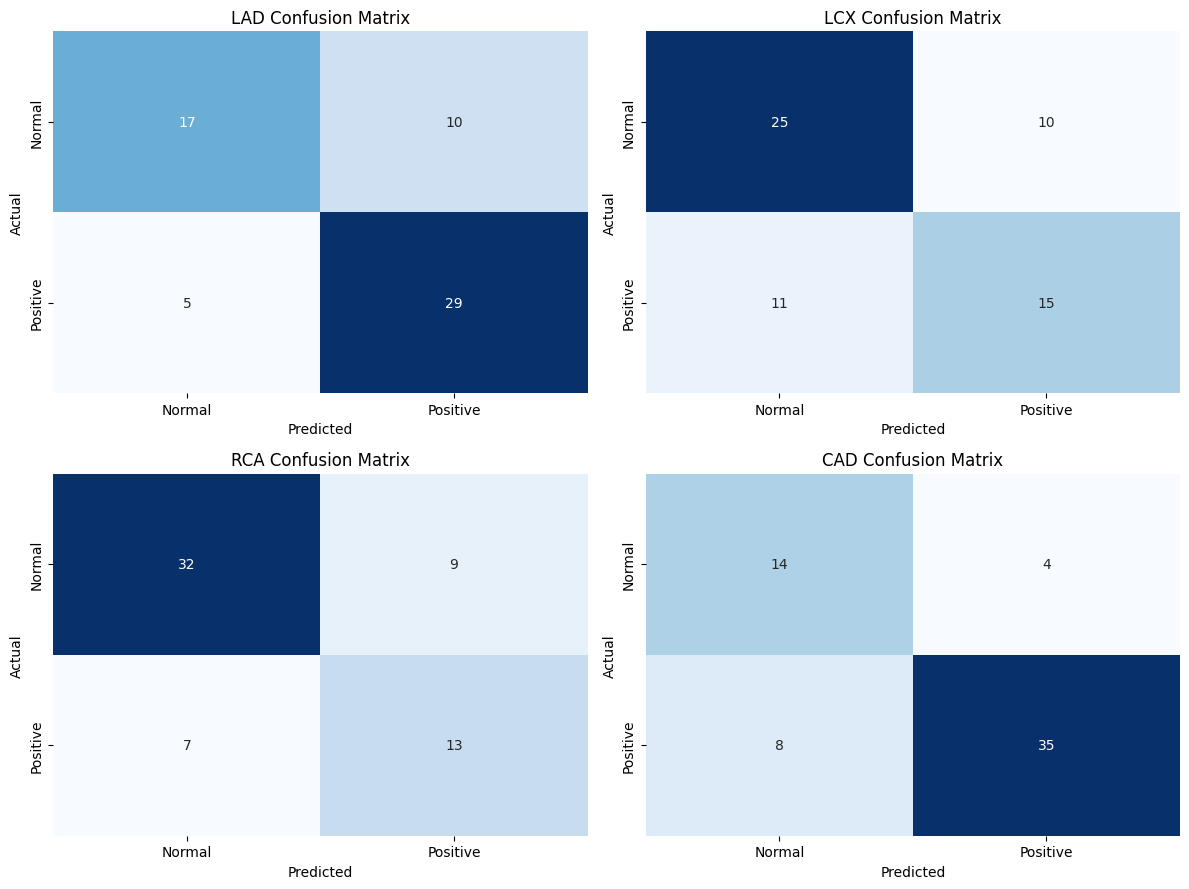

In [ ]:
# Cell 22 — Confusion matrices for all four models

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, target in zip(axes.ravel(), ["LAD", "LCX", "RCA", "CAD"]):

    model = models[target]

    y_pred = model.predict(X_test_processed)

    cm = confusion_matrix(y_test[target], y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=ax,
        xticklabels=["Normal", "Positive"],
        yticklabels=["Normal", "Positive"]
    )

    ax.set_title(f"{target} Confusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

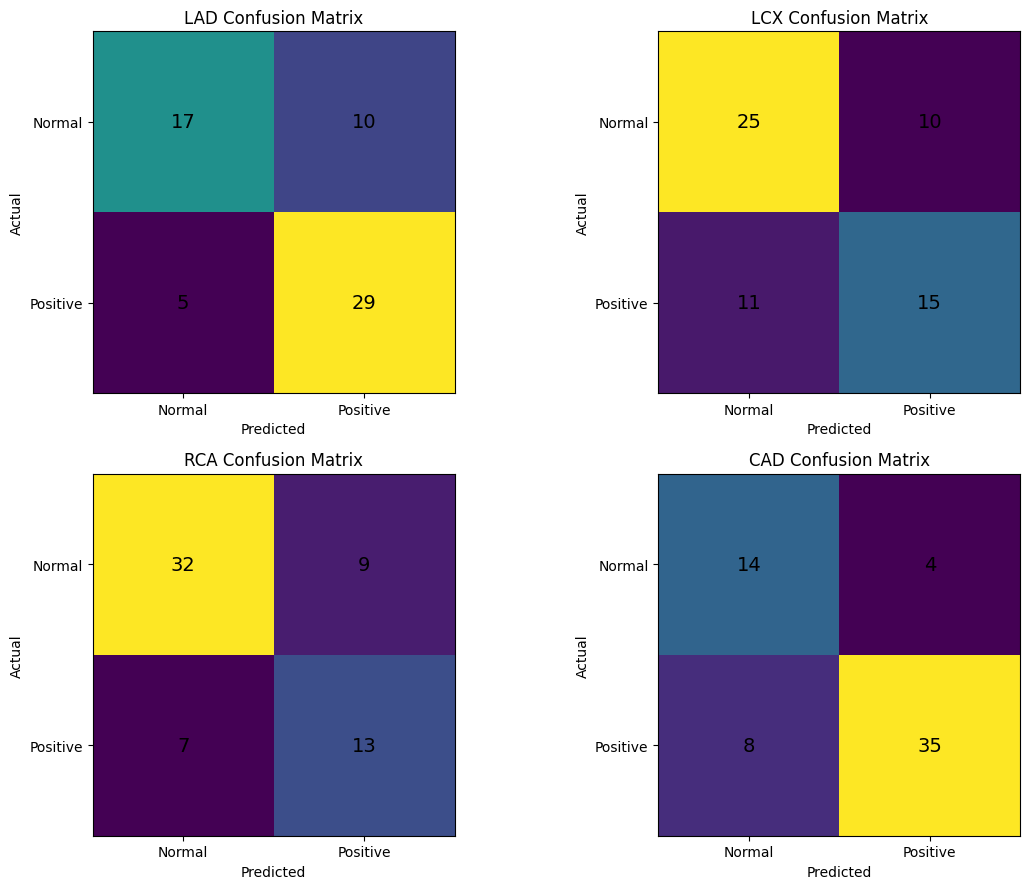

In [ ]:
# Cell 22 — Confusion matrices

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, target in zip(axes.ravel(), ["LAD", "LCX", "RCA", "CAD"]):

    y_pred = models[target].predict(X_test_processed)

    cm = confusion_matrix(y_test[target], y_pred)

    ax.imshow(cm)

    ax.set_title(f"{target} Confusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["Normal", "Positive"])
    ax.set_yticklabels(["Normal", "Positive"])

    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j],
                    ha="center",
                    va="center",
                    fontsize=14)

plt.tight_layout()
plt.show()

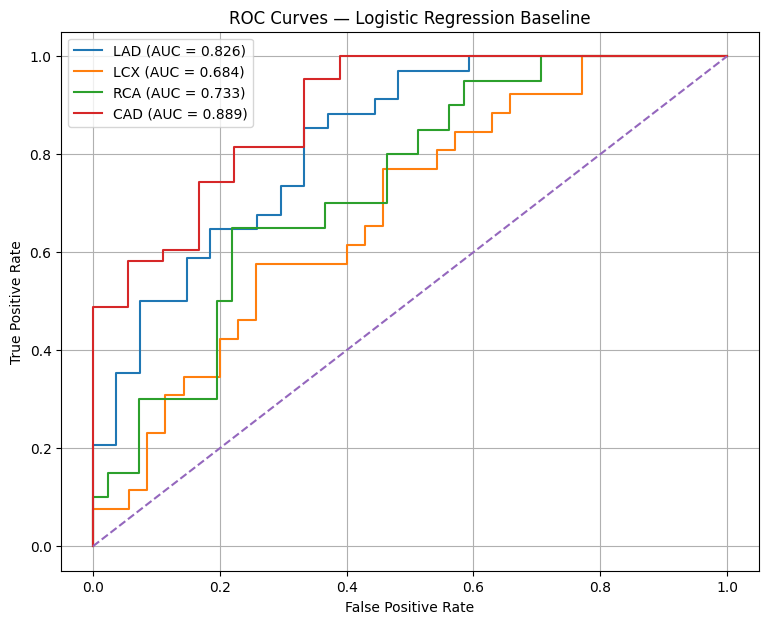

In [ ]:
# Cell 23 — ROC curves for all four models

from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 7))

for target in ["LAD", "LCX", "RCA", "CAD"]:

    model = models[target]

    y_prob = model.predict_proba(X_test_processed)[:, 1]

    fpr, tpr, _ = roc_curve(y_test[target], y_prob)
    auc = roc_auc_score(y_test[target], y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{target} (AUC = {auc:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Logistic Regression Baseline")
plt.legend()
plt.grid(True)
plt.show()

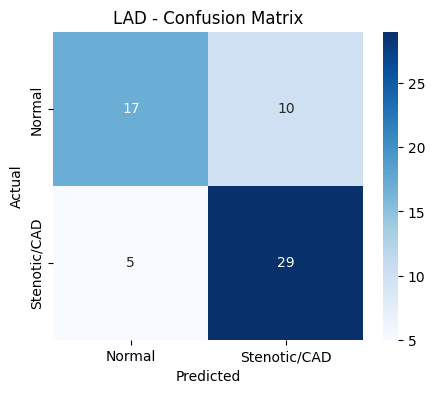

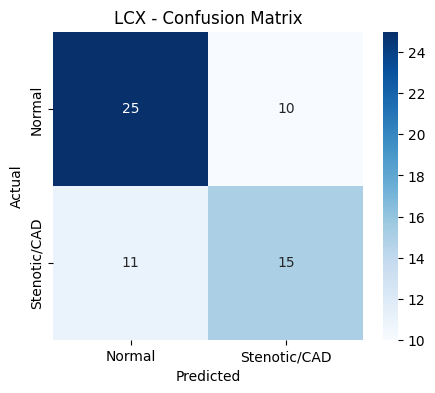

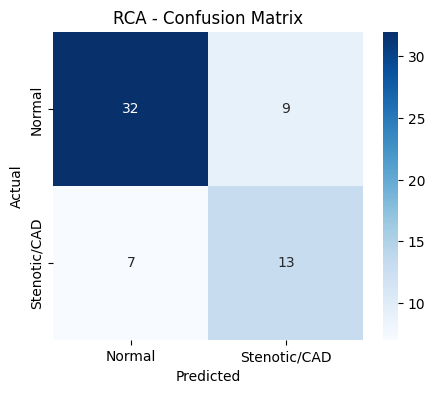

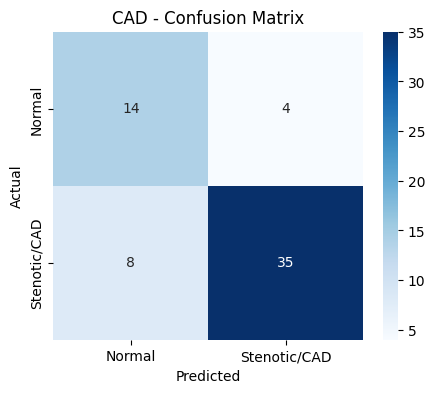

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

for target in ["LAD", "LCX", "RCA", "CAD"]:
    model = models[target]

    y_pred = model.predict(X_test_processed)
    cm = confusion_matrix(y_test[target], y_pred)

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Normal", "Stenotic/CAD"],
        yticklabels=["Normal", "Stenotic/CAD"]
    )

    plt.title(f"{target} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

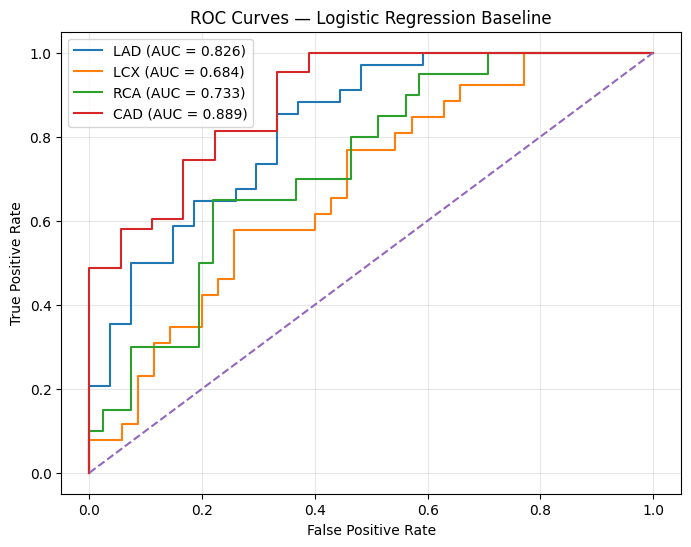

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for target in ["LAD", "LCX", "RCA", "CAD"]:
    model = models[target]

    y_prob = model.predict_proba(X_test_processed)[:, 1]

    fpr, tpr, _ = roc_curve(y_test[target], y_prob)
    auc = roc_auc_score(y_test[target], y_prob)

    plt.plot(fpr, tpr, label=f"{target} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Logistic Regression Baseline")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## **Step 10: Model Development - XGBoost Models**

In [ ]:
from xgboost import XGBClassifier

xgb_models = {}

for target in ["LAD", "LCX", "RCA", "CAD"]:
    model = XGBClassifier(
        n_estimators=150,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=2,
        eval_metric="logloss",
        random_state=42
    )

    model.fit(
        X_train_processed,
        y_train[target]
    )

    xgb_models[target] = model

print("XGBoost models trained successfully.")

XGBoost models trained successfully.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

xgb_results = []

for target in ["LAD", "LCX", "RCA", "CAD"]:
    model = xgb_models[target]

    y_pred = model.predict(X_test_processed)
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    xgb_results.append({
        "Target": target,
        "Accuracy": accuracy_score(
            y_test[target], y_pred
        ),
        "Precision": precision_score(
            y_test[target], y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test[target], y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_test[target], y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test[target], y_prob
        )
    })

xgb_results_df = pd.DataFrame(xgb_results)

xgb_results_df.round(3)

,Target,Accuracy,Precision,Recall,F1,ROC-AUC
0,LAD,0.721,0.718,0.824,0.767,0.790
1,LCX,0.705,0.722,0.500,0.591,0.707
2,RCA,0.689,0.533,0.400,0.457,0.720
3,CAD,0.803,0.830,0.907,0.867,0.868


## **Step 11: Cross-Validation & Model Selection**

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for target in ["LAD", "LCX", "RCA", "CAD"]:

    model = LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    )

    scores = cross_validate(
        model,
        X_train_processed,
        y_train[target],
        cv=cv,
        scoring=[
            "accuracy",
            "precision",
            "recall",
            "f1",
            "roc_auc"
        ],
        n_jobs=-1
    )

    cv_results.append({
        "Target": target,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df.round(3)

,Target,Accuracy,Precision,Recall,F1,ROC-AUC
0,LAD,0.728,0.798,0.720,0.756,0.812
1,LCX,0.620,0.505,0.592,0.543,0.650
2,RCA,0.637,0.532,0.595,0.559,0.705
3,CAD,0.831,0.898,0.860,0.877,0.916


## **Step 12: Train and Save Final Machine Learning Pipelines**

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

final_models = {}

# Final model choices based on our current test results
model_configs = {
    "LAD": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "LCX": XGBClassifier(
        n_estimators=150,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=2,
        eval_metric="logloss",
        random_state=42
    ),

    "RCA": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "CAD": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    )
}

# Build one complete pipeline for each target
for target, model in model_configs.items():

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train[target])

    final_models[target] = pipeline

print("Final pipelines trained successfully.")

for target in final_models:
    print(f"{target}: READY")

Final pipelines trained successfully.
LAD: READY
LCX: READY
RCA: READY
CAD: READY


In [ ]:
import os
import joblib

# Create model directory
os.makedirs("models", exist_ok=True)

# Save each complete pipeline
for target, pipeline in final_models.items():
    path = f"models/{target.lower()}_pipeline.joblib"
    joblib.dump(pipeline, path)
    print(f"Saved: {path}")

print("\nAll models saved successfully.")

Saved: models/lad_pipeline.joblib
Saved: models/lcx_pipeline.joblib
Saved: models/rca_pipeline.joblib
Saved: models/cad_pipeline.joblib

All models saved successfully.


## **Step 13: Export and Download Models**

In [ ]:
import os

for target in ["lad", "lcx", "rca", "cad"]:
    path = f"models/{target}_pipeline.joblib"

    print(
        f"{target.upper()}: "
        f"{os.path.getsize(path) / 1024:.2f} KB"
    )

LAD: 10.99 KB
LCX: 182.44 KB
RCA: 10.99 KB
CAD: 10.99 KB


In [ ]:
!zip -r final_models.zip models/

  adding: models/ (stored 0%)
  adding: models/lcx_pipeline.joblib (deflated 80%)
  adding: models/lad_pipeline.joblib (deflated 65%)
  adding: models/rca_pipeline.joblib (deflated 65%)
  adding: models/cad_pipeline.joblib (deflated 65%)


In [ ]:
from google.colab import files

files.download("final_models.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import sklearn, numpy, scipy, xgboost, joblib

print("scikit-learn:", sklearn.__version__)
print("numpy:", numpy.__version__)
print("scipy:", scipy.__version__)
print("xgboost:", xgboost.__version__)
print("joblib:", joblib.__version__)

scikit-learn: 1.6.1
numpy: 2.1.3
scipy: 1.16.3
xgboost: 3.4.1
joblib: 1.6.0


In [ ]:
import joblib

lcx_pipeline = joblib.load("models/lcx_pipeline.joblib")
print("LCX pipeline loaded in Colab successfully")

LCX pipeline loaded in Colab successfully


In [ ]:
from pathlib import Path

xgb_model = lcx_pipeline.named_steps["model"]

Path("lcx_export").mkdir(exist_ok=True)
xgb_model.save_model("lcx_export/lcx_xgboost.json")

print("LCX XGBoost model exported")

LCX XGBoost model exported


In [ ]:
import joblib
from pathlib import Path
from google.colab import files

export_dir = Path("lcx_export")
export_dir.mkdir(exist_ok=True)

# Save the fitted preprocessing steps separately
joblib.dump(
    lcx_pipeline.named_steps["preprocessor"],
    export_dir / "lcx_preprocessor.joblib"
)

print("Files ready:")
print(list(export_dir.iterdir()))

# Download both files
files.download("lcx_export/lcx_xgboost.json")
files.download("lcx_export/lcx_preprocessor.joblib")

Files ready:
[PosixPath('lcx_export/lcx_preprocessor.joblib'), PosixPath('lcx_export/lcx_xgboost.json')]


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import joblib
from google.colab import files

# Export the fitted preprocessor from the original LCX pipeline
joblib.dump(
    lcx_pipeline.named_steps["preprocessor"],
    "lcx_preprocessor.joblib"
)

# Download the missing file
files.download("lcx_preprocessor.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## **Step 14: Final Out-of-Sample Performance Verification**

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

results = []

for target, pipeline in final_models.items():
    y_true = y_test[target]
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    results.append({
        "Target": target,
        "Accuracy": round(accuracy_score(y_true, y_pred), 3),
        "Precision": round(precision_score(
            y_true, y_pred, zero_division=0
        ), 3),
        "Recall": round(recall_score(
            y_true, y_pred, zero_division=0
        ), 3),
        "F1": round(f1_score(
            y_true, y_pred, zero_division=0
        ), 3),
        "ROC-AUC": round(roc_auc_score(y_true, y_prob), 3),
        "True Positive": tp,
        "False Negative": fn,
        "True Negative": tn,
        "False Positive": fp
    })

evaluation = pd.DataFrame(results)
display(evaluation)

,Target,Accuracy,Precision,Recall,F1,ROC-AUC,True Positive,False Negative,True Negative,False Positive
0,LAD,0.754,0.744,0.853,0.795,0.826,29,5,17,10
1,LCX,0.705,0.722,0.500,0.591,0.707,13,13,30,5
2,RCA,0.738,0.591,0.650,0.619,0.733,13,7,32,9
3,CAD,0.803,0.897,0.814,0.854,0.889,35,8,14,4
